# Opening the published ECMWF IFS Icechunk store (source.coop)

The ECMWF IFS ensemble GIK store is published on **source.coop** as a virtual
Icechunk repo. Its metadata (repo pointer + snapshots + manifests + transactions)
lives on source.coop; the actual data chunks are **virtual references** into the
public `s3://ecmwf-forecasts/` GRIB archive on AWS. A reader needs only:

- **anonymous** GET/LIST on source.coop (the store metadata), and
- **anonymous** GET on `ecmwf-forecasts` (the GRIB bytes the virtual chunks point at).

| | value |
|---|---|
| Endpoint | `https://data.source.coop` |
| Bucket | `e4drr-project` |
| Prefix | `forecasts/ecmwf_ifs_ens_aws_s3_icechunk_vd` |
| Virtual container | `s3://ecmwf-forecasts/` |
| Groups | `{era}/{cycle}` -- **3 eras x 4 cycles = 12** |
| Indexed | **5,230 date-cycles**, 51 members each |
| Referenced GRIB | **1.615 PB** (store objects themselves: ~15 GB) |

> **Correction, 2026-08-27.** The previous version of this notebook opened only
> `{era}/00z` and described the store as 00z-only. It is not: all four daily cycles
> are indexed, in every era. That earlier reading came from treating the `00z` in the
> group path as fixed rather than as one of four values -- a single
> `list(group.group_keys())` disproves it. Section 2 does exactly that, first, before
> anything else assumes a layout.


## Dependencies

```
icechunk>=2.1  zarr>=3.2  xarray>=2025.1  gribberish>=1.4  s3fs  numpy  matplotlib  pandas
```

No credentials of any kind are required: this notebook reads the store metadata
anonymously from source.coop and the GRIB bytes anonymously from AWS.


In [1]:
%matplotlib inline

import asyncio
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import icechunk
import zarr
import xarray as xr
import gribberish.zarr  # noqa: F401 -- registers the "gribberish" Zarr v3 codec

print("icechunk", icechunk.__version__)
print("xarray  ", xr.__version__)


icechunk 2.1.1
xarray   2026.7.0


## 1. Open the store

Anonymous throughout -- `force_path_style=True`, `from_env=False`, manifest preload
off, and `decode_timedelta=True` on `open_zarr`. All four are explained in
**Gotchas** at the bottom. The repo is opened once; each group is then a separate
`open_zarr` call against the same session.


In [2]:
ENDPOINT  = "https://data.source.coop"
BUCKET    = "e4drr-project"
PREFIX    = "forecasts/ecmwf_ifs_ens_aws_s3_icechunk_vd"
CONTAINER = "s3://ecmwf-forecasts/"     # virtual chunks (public AWS, anon)

t0 = time.time()

storage = icechunk.s3_storage(
    bucket=BUCKET, prefix=PREFIX, endpoint_url=ENDPOINT, region="us-east-1",
    anonymous=True,          # public read of the store metadata
    from_env=False,          # ignore any AWS_* env vars
    force_path_style=True,   # source.coop needs path-style addressing
)

# The GRIB bytes live in a different bucket; authorize it explicitly, also anonymous.
auth = icechunk.containers_credentials({CONTAINER: icechunk.s3_anonymous_credentials()})

cfg = icechunk.RepositoryConfig.default()
cfg.manifest = icechunk.ManifestConfig(
    preload=icechunk.ManifestPreloadConfig(max_total_refs=0, max_arrays_to_scan=0))

repo = icechunk.Repository.open(storage, config=cfg,
                                authorize_virtual_chunk_access=auth)
sess = repo.readonly_session("main")
print(f"opened in {time.time() - t0:.1f}s")


opened in 3.5s


## 2. What is in it -- ask, do not assume

The store nests `{era}/{cycle}`. Enumerating the groups is one cheap call and it is
the step that keeps you honest about the layout:


In [3]:
root = zarr.open_group(sess.store, mode="r")
ERAS = sorted(root.group_keys())

for era in ERAS:
    cycles = sorted(zarr.open_group(sess.store, mode="r", path=era).group_keys())
    print(f"{era:5s} cycles: {cycles}")

anc = list(repo.ancestry(branch="main"))
print(f"\n{len(anc):,} snapshots   HEAD {str(anc[0].id)[:16]}")
print(f"latest write: {str(anc[0].written_at)[:19]}  {anc[0].message[:55]}")


0p4   cycles: ['00z', '06z', '12z', '18z']
49r1  cycles: ['00z', '06z', '12z', '18z']
50r1  cycles: ['00z', '06z', '12z', '18z']



3,787 snapshots   HEAD CSG8BX0ZMZMF8Q09
latest write: 2026-08-25 12:41:53  50r1/18z 20260823: 51 members, 410525 refs (time index 


In [4]:
CYCLES = ["00z", "06z", "12z", "18z"]

def open_group(era, cycle):
    """Arrays live at {era}/{cycle} -- never at the root, never at a bare {era}."""
    return xr.open_zarr(sess.store, group=f"{era}/{cycle}", zarr_format=3,
                        consolidated=False, chunks=None, decode_timedelta=True)

rows = []
for era in ERAS:
    for cyc in CYCLES:
        d = open_group(era, cyc)
        t = pd.to_datetime(d.time.values)
        rows.append(dict(era=era, cycle=cyc, dates=len(t), steps=d.sizes["step"],
                         vars=len(d.data_vars), members=d.sizes["number"],
                         grid=f'{d.sizes["latitude"]}x{d.sizes["longitude"]}',
                         first=str(t.min().date()), last=str(t.max().date())))

inv = pd.DataFrame(rows)
print(inv.to_string(index=False))
print(f"\ntotal date-cycles: {inv.dates.sum():,}")


 era cycle  dates  steps  vars  members     grid      first       last
 0p4   00z    401     85    19       51  451x900 2023-01-18 2024-02-28
 0p4   06z    400     49    19       51  451x900 2023-01-18 2024-02-27
 0p4   12z    399     85    19       51  451x900 2023-01-18 2024-02-27
 0p4   18z    399     49    19       51  451x900 2023-01-18 2024-02-27
49r1   00z    804     85    59       51 721x1440 2024-02-29 2026-05-12
49r1   06z    804     49    59       51 721x1440 2024-02-28 2026-05-11
49r1   12z    804     85    59       51 721x1440 2024-02-28 2026-05-11
49r1   18z    804     49    57       51 721x1440 2024-02-28 2026-05-11
50r1   00z    103     85    54       51 721x1440 2026-05-13 2026-08-23
50r1   06z    104     49    54       51 721x1440 2026-05-12 2026-08-23
50r1   12z    104     85    54       51 721x1440 2026-05-12 2026-08-23
50r1   18z    104     49    54       51 721x1440 2026-05-12 2026-08-23

total date-cycles: 5,230


Three oddities in that table, all explained further down and only one of them a
defect:

- **`steps` is 85 at 00z/12z but 49 at 06z/18z** -- correct. Section 6.
- **`49r1/18z` has 57 vars, not 59** -- correct, and the *safe* case. Section 5.
- **06z/12z/18z start a day before 00z** -- correct. Section 7.


## 3. The current era and cycle: `50r1/00z`


In [5]:
ds = open_group("50r1", "00z")
print(ds)


<xarray.Dataset> Size: 341TB
Dimensions:        (time: 103, number: 51, step: 85, latitude: 721,
                    longitude: 1440, isobaricInhPa: 14)
Coordinates:
  * time           (time) datetime64[ns] 824B 2026-05-13 ... 2026-08-23
  * number         (number) int16 102B 0 1 2 3 4 5 6 7 ... 44 45 46 47 48 49 50
  * step           (step) timedelta64[ns] 680B 0 days 00:00:00 ... 15 days 00...
  * latitude       (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude      (longitude) float64 12kB -180.0 -179.8 -179.5 ... 179.5 179.8
  * isobaricInhPa  (isobaricInhPa) float64 112B 10.0 50.0 100.0 ... 925.0 1e+03
Data variables: (12/54)
    100u           (time, number, step, latitude, longitude) float32 2TB ...
    10fg3          (time, number, step, latitude, longitude) float32 2TB ...
    ewss           (time, number, step, latitude, longitude) float32 2TB ...
    d              (time, number, step, isobaricInhPa, latitude, longitude) float32 26TB ...
    gh     

## 4. Size: four numbers, do not conflate them

| measure | size | meaning |
|---|---|---|
| store objects on source.coop | ~15 GB | what is actually hosted -- pointers, not data |
| **referenced GRIB, all 12 groups** | **1.615 PB** | bytes pulled reading the whole store once |
| referenced GRIB, 00z only | 512 TB | the subset the old notebook measured |
| dense float32 (`sum(ds.nbytes)`) | ~9 PB | every cell materialized -- **misleading** |

`ds.nbytes` assumes every cell exists, uncompressed. GRIB is packed and the archive
is not dense, so it overstates by ~5.6x. Use the **referenced** number for *how much
data is this*.

Broken out by era and cycle (measured by listing every `.grib2` object for all 5,230
date-cycles -- see the companion notebook `ECMWF_IFS_FOUR_CYCLES_SIZE.ipynb` for the
sweep itself):

| era | 00z | 06z | 12z | 18z | total |
|---|---|---|---|---|---|
| `0p4` | 64.3 | 36.8 | 63.8 | 36.6 | 201.5 TB |
| `49r1` | 389.7 | 224.8 | 390.0 | 224.9 | 1,229.4 TB |
| `50r1` | 58.5 | 33.7 | 58.5 | 33.7 | 184.4 TB |
| **all** | **512.5** | **295.3** | **512.3** | **295.2** | **1,615.3 TB** |


In [6]:
dense = sum(open_group(e, c).nbytes for e in ERAS for c in CYCLES)
print(f"dense float32, all 12 groups : {dense/1e15:6.2f} PB")
print(f"referenced GRIB (packed)     : {1.6153:6.3f} PB")
print(f"inflation factor             : {dense/1.6153e15:6.1f}x")


dense float32, all 12 groups :   9.42 PB
referenced GRIB (packed)     :  1.615 PB
inflation factor             :    5.8x


## 5. Coverage: an array can exist and still be empty

**This is the trap worth internalising before using the store for anything.**

The `time` axis is preallocated to the whole era. A date that was never written is
therefore not absent -- it is on the axis, `.sel()` finds it, and it reads back as
all-NaN. Nothing raises.

`49r1` shows both the safe and the unsafe version of this, in sibling cycles:


In [7]:
async def written_dates(path, attempts=5):
    """Time indices this array has chunks for. Manifest only -- reads no data.

    Retried: source.coop returns sporadic 500s, and one mid-scan aborts the whole
    enumeration. Without the retry this cell fails perhaps one run in three.
    """
    for attempt in range(attempts):
        try:
            out = set()
            async for c in sess.chunk_coordinates(path):
                out.add(tuple(c)[0])
            return out
        except Exception:
            if attempt == attempts - 1:
                raise
            await asyncio.sleep(2 ** attempt)

for cyc in CYCLES:
    d = open_group("49r1", cyc)
    for v in ("mn2t6", "mx2t6"):
        if v not in d.data_vars:
            print(f"  49r1/{cyc}/{v:6s}: ARRAY ABSENT        -- honest: .data_vars says so")
            continue
        n = len(await written_dates(f"/49r1/{cyc}/{v}"))
        flag = "  <-- EMPTY: every read returns NaN" if n == 0 else ""
        print(f"  49r1/{cyc}/{v:6s}: {n:4d} dates written{flag}")


  49r1/00z/mn2t6 :  546 dates written


  49r1/00z/mx2t6 :  546 dates written


  49r1/06z/mn2t6 :    0 dates written  <-- EMPTY: every read returns NaN
  49r1/06z/mx2t6 :    0 dates written  <-- EMPTY: every read returns NaN


  49r1/12z/mn2t6 :  546 dates written


  49r1/12z/mx2t6 :  546 dates written


  49r1/18z/mn2t6 : ARRAY ABSENT        -- honest: .data_vars says so
  49r1/18z/mx2t6 : ARRAY ABSENT        -- honest: .data_vars says so


In [8]:
d = open_group("49r1", "06z")
t = pd.to_datetime(d.time.values)
ti = int(np.argmin(np.abs(t - pd.Timestamp("2025-06-01"))))
field = d["mn2t6"].isel(time=ti, number=0, step=2).values

print(f"49r1/06z mn2t6 @ {t[ti].date()}")
print(f"  shape {field.shape}   finite fraction {np.isfinite(field).mean():.3f}")
print("  -> the selection SUCCEEDS and returns an all-NaN field.")


49r1/06z mn2t6 @ 2025-06-01
  shape (721, 1440)   finite fraction 0.000
  -> the selection SUCCEEDS and returns an all-NaN field.


`49r1/18z` omits the arrays, so `.data_vars` tells you and code that needs them fails
loudly. `49r1/06z` advertises them and hands back NaN -- there is no API-level way to
tell *never published for this cycle* from *no data*.

Partial coverage is normal even where a variable is populated, because ECMWF adds
fields over time:


In [9]:
d = open_group("49r1", "00z")
t = pd.to_datetime(d.time.values)
idx = sorted(await written_dates("/49r1/00z/mn2t6"))
print(f"49r1/00z/mn2t6 covers {len(idx)} of {len(t)} dates")
print(f"  first written {t[idx[0]].date()}   last {t[idx[-1]].date()}")
print(f"  the {len(t)-len(idx)} earlier dates on the axis read as NaN")


49r1/00z/mn2t6 covers 546 of 804 dates
  first written 2024-11-13   last 2026-05-12
  the 258 earlier dates on the axis read as NaN


**Check coverage from the manifest, not from `.data_vars` or `ds.sizes`.**
`session.chunk_coordinates` enumerates exactly which chunks exist without fetching
any of them -- it is the only cheap way to tell an empty array from a full one.


## 6. The cycles are not four equal quarters

ECMWF runs the ensemble to **+360 h at 00z and 12z** but only to **+144 h at 06z and
18z**. Same 51 members, same grid, roughly half the lead times -- which is why `steps`
is 85 or 49 in the inventory:


In [10]:
for cyc in CYCLES:
    d = open_group("50r1", cyc)
    last_h = float(d.step.values[-1] / np.timedelta64(1, "h"))
    print(f"  50r1/{cyc}: {d.sizes['step']:2d} steps, out to +{last_h:.0f}h")

print("\nreferenced GRIB per cycle, whole store (TB):  512.5 / 295.3 / 512.3 / 295.2")
print("ratio to 00z:                                1.000 / 0.576 / 0.999 / 0.576")
print("sum = 3.15x a single 00z run, NOT 4x")


  50r1/00z: 85 steps, out to +360h


  50r1/06z: 49 steps, out to +144h


  50r1/12z: 85 steps, out to +360h


  50r1/18z: 49 steps, out to +144h

referenced GRIB per cycle, whole store (TB):  512.5 / 295.3 / 512.3 / 295.2
ratio to 00z:                                1.000 / 0.576 / 0.999 / 0.576
sum = 3.15x a single 00z run, NOT 4x


Anyone sizing four-cycle coverage by multiplying a 00z figure by four overshoots by
about **27%**.


## 7. An era is not a whole number of days

In the inventory, `49r1`'s 06z/12z/18z begin on **2024-02-28** while its 00z begins on
**2024-02-29**. That is not an off-by-one: the schema switch happened *between the
00z and 06z runs of the same morning*.


In [11]:
for era in ("0p4", "49r1"):
    spans = {c: pd.to_datetime(open_group(era, c).time.values) for c in CYCLES}
    print(f"{era:5s} " + "   ".join(
        f"{c} {v.min().date()}..{v.max().date()}" for c, v in spans.items()))

print("\n-> 2024-02-28 00z is the last 0p4 run;")
print("   2024-02-28 06z/12z/18z are already 49r1.")


0p4   00z 2023-01-18..2024-02-28   06z 2023-01-18..2024-02-27   12z 2023-01-18..2024-02-27   18z 2023-01-18..2024-02-27


49r1  00z 2024-02-29..2026-05-12   06z 2024-02-28..2026-05-11   12z 2024-02-28..2026-05-11   18z 2024-02-28..2026-05-11

-> 2024-02-28 00z is the last 0p4 run;
   2024-02-28 06z/12z/18z are already 49r1.


`0p4/12z` and `0p4/18z` are also two dates shorter than `0p4/00z`. Besides the era
boundary above, **2023-04-26** is missing from both: ECMWF published only 00z and 06z
that day. The store reflects the archive faithfully -- there is nothing to index.


## 8. Read one field

This resolves a virtual chunk: icechunk maps the index to a byte range in a GRIB file
on `ecmwf-forecasts`, fetches just those bytes, and gribberish decodes the message.


In [12]:
ds = open_group("50r1", "00z")
ti = int(np.argmax(ds["time"].values))          # newest run in 50r1/00z
newest = np.datetime_as_string(ds["time"].values[ti], unit="D")

t1 = time.time()
t2m = ds["t2m"].isel(time=ti, number=0, step=0).compute()   # control member, f000
print(f"t2m @ {newest}, member 0 (control), f000")
print(f"  shape {t2m.shape} decoded in {time.time() - t1:.2f}s")
print(f"  finite fraction {np.isfinite(t2m.values).mean():.3f}")
print(f"  min/mean/max = {float(t2m.min()):.4g} / {float(t2m.mean()):.4g} / "
      f"{float(t2m.max()):.4g} K")


t2m @ 2026-08-23, member 0 (control), f000
  shape (721, 1440) decoded in 1.76s
  finite fraction 1.000
  min/mean/max = 208.5 / 281.2 / 320.2 K


In [13]:
def plot_field(field, title, cbar_label, cmap="viridis", levels=21):
    """Filled contour of a (latitude, longitude) DataArray on a plain lat/lon grid."""
    fig, ax = plt.subplots(figsize=(12, 5.5))
    m = ax.contourf(field["longitude"], field["latitude"], field.values,
                    levels=levels, cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("longitude (deg east)")
    ax.set_ylabel("latitude (deg north)")
    ax.set_aspect("equal")
    fig.colorbar(m, ax=ax, label=cbar_label, shrink=0.85)
    plt.tight_layout()
    plt.show()


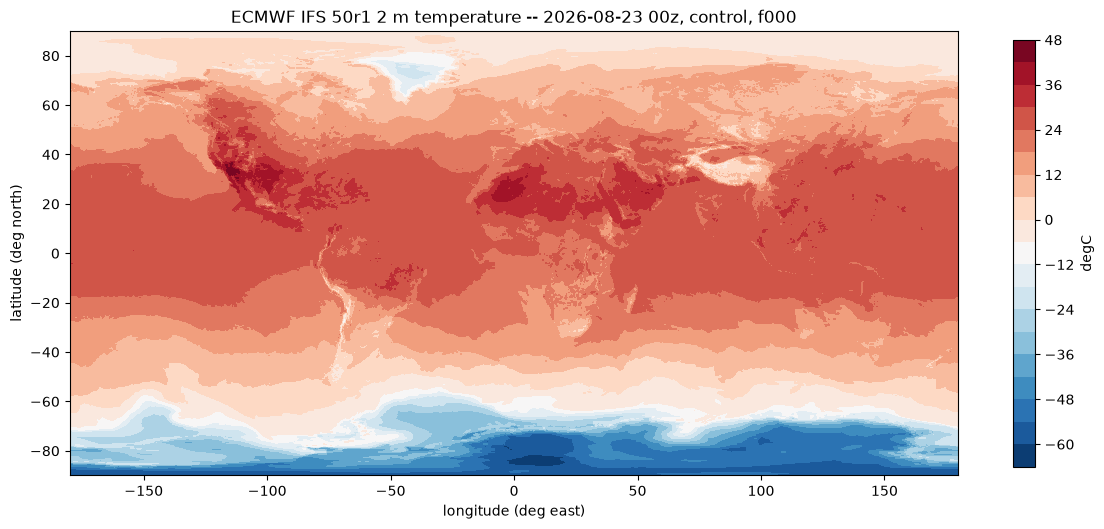

In [14]:
plot_field(t2m - 273.15,
           f"ECMWF IFS 50r1 2 m temperature -- {newest} 00z, control, f000",
           "degC", cmap="RdBu_r")


### The same field from a different cycle

Nothing changes but the group name -- and note the 18z run only reaches +144 h, so a
long-lead selection that works at 00z will raise here.


In [15]:
d18 = open_group("50r1", "18z")
ti18 = int(np.argmax(d18["time"].values))
t2m18 = d18["t2m"].isel(time=ti18, number=0, step=0).compute()
print(f"50r1/18z t2m @ {np.datetime_as_string(d18['time'].values[ti18], unit='D')}")
print(f"  min/mean/max = {float(t2m18.min()):.4g} / {float(t2m18.mean()):.4g} / "
      f"{float(t2m18.max()):.4g} K")
print(f"  max lead time here: +{float(d18.step.values[-1] / np.timedelta64(1,'h')):.0f}h "
      f"(00z reaches +{float(ds.step.values[-1] / np.timedelta64(1,'h')):.0f}h)")


50r1/18z t2m @ 2026-08-23
  min/mean/max = 208.6 / 281.5 / 320.1 K
  max lead time here: +144h (00z reaches +360h)


## 9. The height layer

Unlike GEFS (single-level only), the ECMWF store has a real vertical dimension:
`isobaricInhPa`. In `50r1` that is 14 pressure levels from 10 to 1000 hPa, and the
3-D variables (`gh`, `t`, `u`, `v`, `w`, `q`, `r`, `d`, `vo`, `z`) carry it as a
dimension.

Selecting a level costs one chunk, not the whole column.


In [16]:
print("levels (hPa):", ds["isobaricInhPa"].values)
print()
print("3-D vars (have isobaricInhPa):")
print("  ", ", ".join(sorted(v for v in ds.data_vars
                             if "isobaricInhPa" in ds[v].dims)))
print("gh dims:", ds["gh"].dims)


levels (hPa): [  10.   50.  100.  150.  200.  250.  300.  400.  500.  600.  700.  850.
  925. 1000.]

3-D vars (have isobaricInhPa):
   d, gh, q, r, t, u, v, vo, w, z
gh dims: ('time', 'number', 'step', 'isobaricInhPa', 'latitude', 'longitude')


In [17]:
t1 = time.time()
gh500 = ds["gh"].sel(isobaricInhPa=500).isel(time=ti, number=0, step=0).compute()
print(f"gh @ 500 hPa decoded in {time.time() - t1:.2f}s -- shape {gh500.shape}")
print(f"  min/mean/max = {float(gh500.min()):.0f} / {float(gh500.mean()):.0f} / "
      f"{float(gh500.max()):.0f} m")


gh @ 500 hPa decoded in 3.49s -- shape (721, 1440)
  min/mean/max = 4659 / 5567 / 5993 m


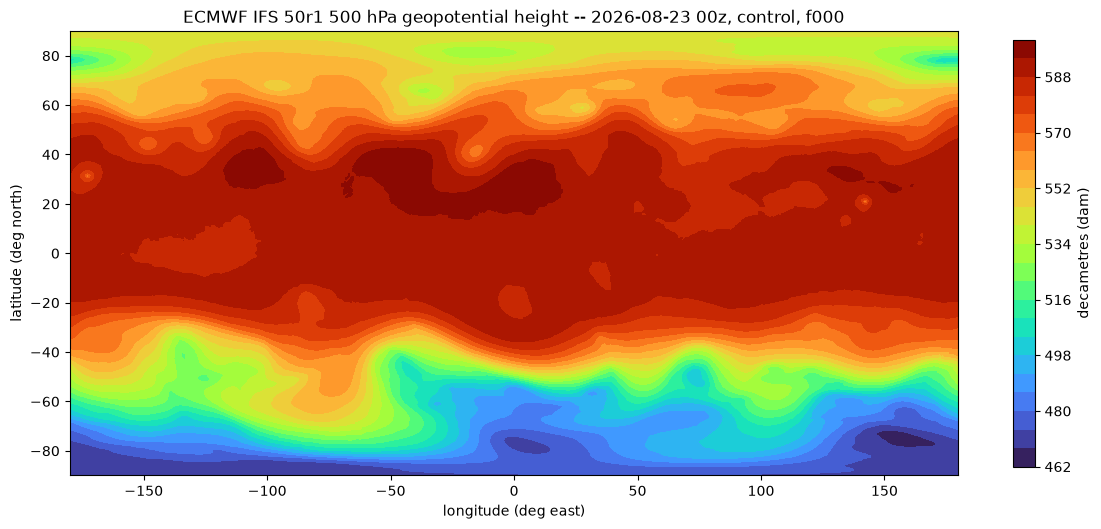

In [18]:
plot_field(gh500 / 10.0,
           f"ECMWF IFS 50r1 500 hPa geopotential height -- {newest} 00z, control, f000",
           "decametres (dam)", cmap="turbo", levels=25)


### The whole vertical column, for free

Because the level is just another dimension, a profile is an ordinary selection. This
pulls all 14 levels at one grid point -- 14 chunk resolutions, still no full array.


14-level temperature profile decoded in 1.8s


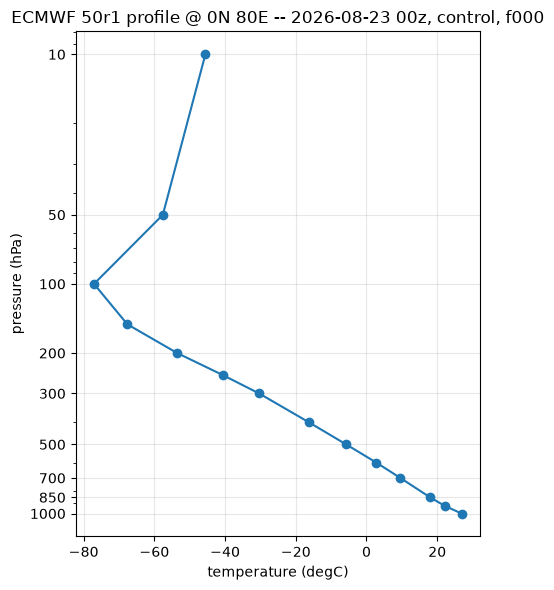

In [19]:
t1 = time.time()
prof = ds["t"].isel(time=ti, number=0, step=0).sel(
    latitude=0, longitude=80, method="nearest").compute()
print(f"14-level temperature profile decoded in {time.time() - t1:.1f}s")

fig, ax = plt.subplots(figsize=(5, 6))
ax.plot(prof.values - 273.15, prof["isobaricInhPa"].values, marker="o")
ax.invert_yaxis()
ax.set_yscale("log")
ax.set_yticks([10, 50, 100, 200, 300, 500, 700, 850, 1000])
ax.set_yticklabels([10, 50, 100, 200, 300, 500, 700, 850, 1000])
ax.set_xlabel("temperature (degC)")
ax.set_ylabel("pressure (hPa)")
ax.set_title(f"ECMWF 50r1 profile @ 0N 80E -- {newest} 00z, control, f000")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Gotchas

- **Enumerate `group_keys()`; do not hardcode the layout.** Groups are `{era}/{cycle}`
  and there are twelve. Assuming `00z` is how the previous version of this notebook
  concluded that three quarters of the store did not exist.
- **Arrays are under `{era}/{cycle}`, never the root.** Opening the root group is
  empty; opening a bare `era` group is empty too -- you need `50r1/00z`, `49r1/18z`,
  and so on.
- **An array can exist and be empty.** `49r1/06z/mn2t6` selects fine and returns
  all-NaN. `.data_vars` cannot tell you; `session.chunk_coordinates` can, from the
  manifest, without reading a chunk. Partial coverage is normal too -- `mn2t6` starts
  2024-11-13, so 258 dates of `49r1/00z` read as NaN.
- **`06z`/`18z` stop at +144 h**, `00z`/`12z` reach +360 h. A long-lead selection that
  works on one cycle raises on another, and any size estimate treating the four cycles
  as equal is ~27% too large.
- **An era is not a whole number of days.** The `0p4` -> `49r1` switch falls between
  the 00z and 06z runs of 2024-02-28.
- **Pass `decode_timedelta=True`.** Otherwise xarray raises a `FutureWarning` about
  decoding `step` from its timedelta-like `units` attribute -- historically it guessed,
  and that guess is being removed.
- **Variable names can differ by era.** All three eras here expose 2 m temperature as
  `t2m`, but the raw ECMWF short name (`2t`, `10u`) shows up in other GIK builds. Probe
  with `next(v for v in ('t2m', '2t') if v in ds)` rather than hard-coding, if you write
  code meant to survive a rebuild.
- **`gribberish.zarr` must be imported** before reading any chunk (it registers the
  Zarr v3 codec) -- otherwise even opening a group fails with
  `UnknownCodecError: 'gribberish'` while reading array metadata.
- **Authorize the virtual chunk container.** Without
  `authorize_virtual_chunk_access`, reading a chunk fails with *a virtual chunk in
  this repository resolves to the url prefix s3://ecmwf-forecasts/*. Opening the store
  succeeds; only the read fails.
- **Disable the manifest preload.** The default open prefetches thousands of manifests
  in parallel and source.coop returns sporadic 500s, so one of them tends to fail the
  whole open.
- **Reading a `49r1` pressure-level variable needs >6 GB RAM** for a full-globe,
  all-member selection. Select `number` and `step` before `.compute()`.
- **Do not quote `ds.nbytes`** as the data volume -- it is ~5.6x the packed size and
  describes a dense array that does not exist. The store references **1.615 PB** of
  GRIB while hosting ~15 GB of pointers.
